# Formative 2 - Task 2: Image Data Collection and Processing

**Goal:** collect 3 facial expressions per team member, display them, augment every image, and save features to `data/image_features.csv`.

**Naming convention:** `images/<member>_<neutral|smiling|surprised>.jpg`. The notebook works from the repository root automatically.

In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":   # always work from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, "src")
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import image_pipeline as ip

IMAGES = Path("images")
items = ip.load_images(IMAGES)
members = sorted({i["member"] for i in items})
print(f"{len(items)} images, {len(members)} members: {members}")

9 images, 3 members: ['aderline', 'elox', 'sandrine']


## 1. Dataset check: quantity and diversity
Every member should have exactly the three required expressions.

In [2]:
check = (pd.DataFrame([{"member": i["member"], "expression": i["expression"]} for i in items])
         .assign(n=1).pivot_table(index="member", columns="expression", values="n", aggfunc="sum", fill_value=0))
check = check.reindex(columns=list(ip.EXPRESSIONS), fill_value=0)
display(check)
assert (check.values == 1).all(), "Each member needs exactly one neutral, one smiling and one surprised image"
print("All members have neutral, smiling and surprised images.")

expression,neutral,smiling,surprised
member,,,
aderline,1,1,1
elox,1,1,1
sandrine,1,1,1


All members have neutral, smiling and surprised images.


## 2. Load and display sample pictures of each member

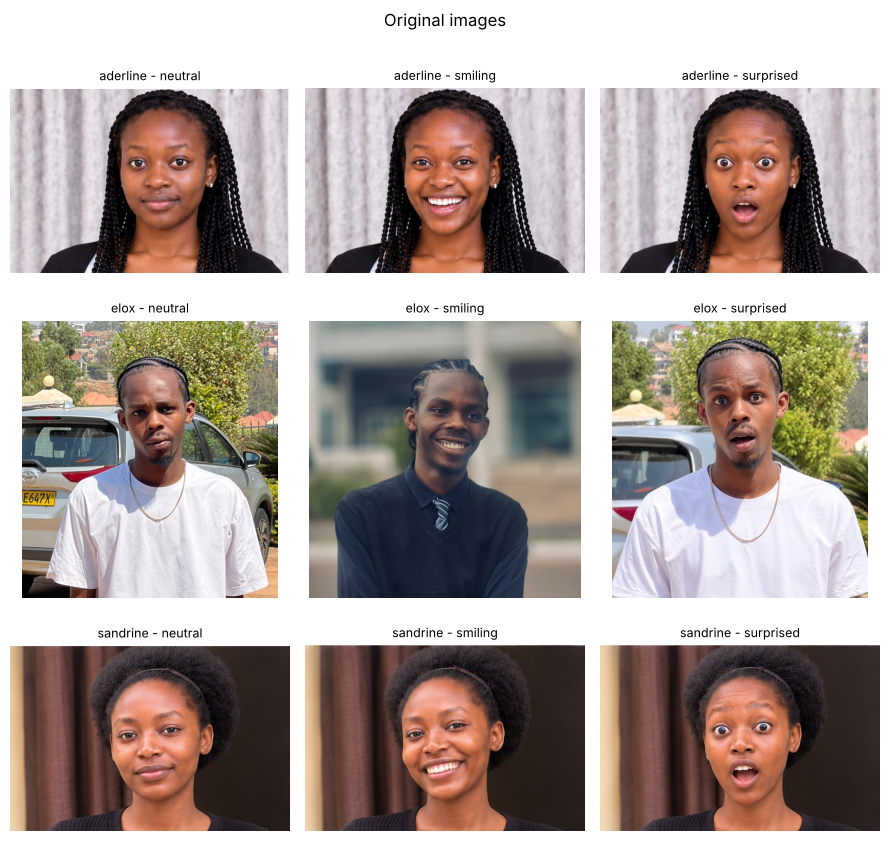

In [3]:
n_rows, n_cols = len(members), len(ip.EXPRESSIONS)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3*n_cols, 3*n_rows), squeeze=False)
for r, m in enumerate(members):
    for c, e in enumerate(ip.EXPRESSIONS):
        it = next(i for i in items if i["member"] == m and i["expression"] == e)
        axes[r][c].imshow(cv2.cvtColor(it["bgr"], cv2.COLOR_BGR2RGB))
        axes[r][c].set_title(f"{m} - {e}", fontsize=9); axes[r][c].axis("off")
plt.suptitle("Original images"); plt.tight_layout(); plt.show()

## 3. Preprocessing: face crop and resize
Faces are cropped with OpenCV's Haar detector (largest face), resized to 128x128 and converted to grayscale so every image has the same shape and colour mode. If no face is found, the full image is used.

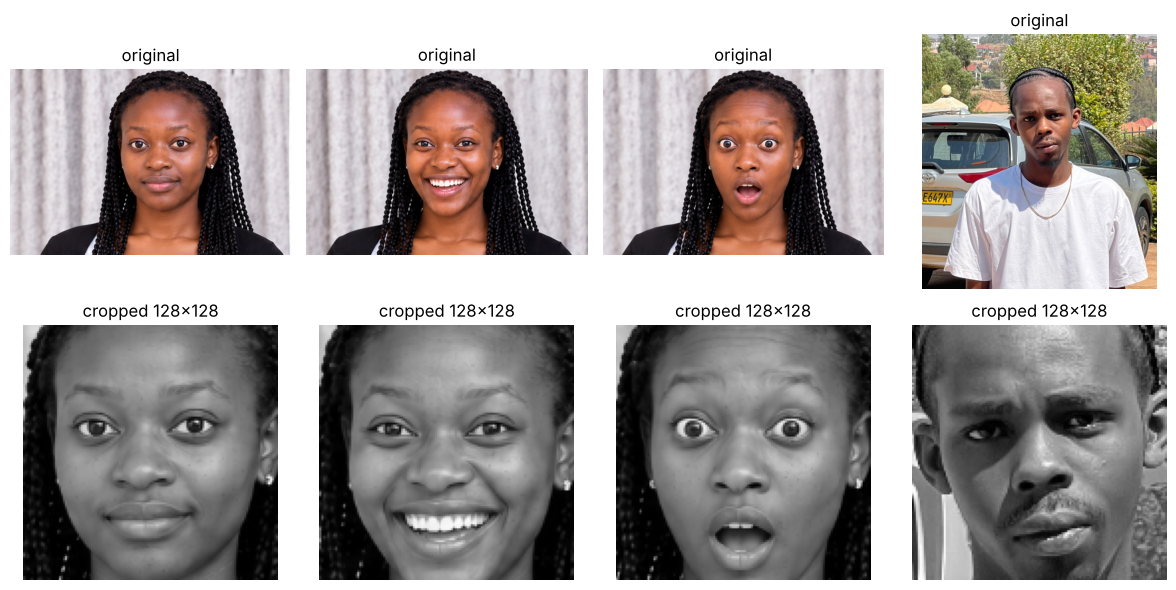

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, it in zip(axes.ravel(), items[:4]):
    ax.imshow(cv2.cvtColor(it["bgr"], cv2.COLOR_BGR2RGB)); ax.set_title("original"); ax.axis("off")
for ax, it in zip(axes.ravel()[4:], items[:4]):
    ax.imshow(cv2.cvtColor(ip.crop_face(it["bgr"]), cv2.COLOR_BGR2RGB)); ax.set_title("cropped 128x128"); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Augmentations
Each image gets 5 augmented versions plus the original: rotation (+15 and -15 degrees), horizontal flip, Gaussian blur and brightness increase. The rubric asks for at least two.

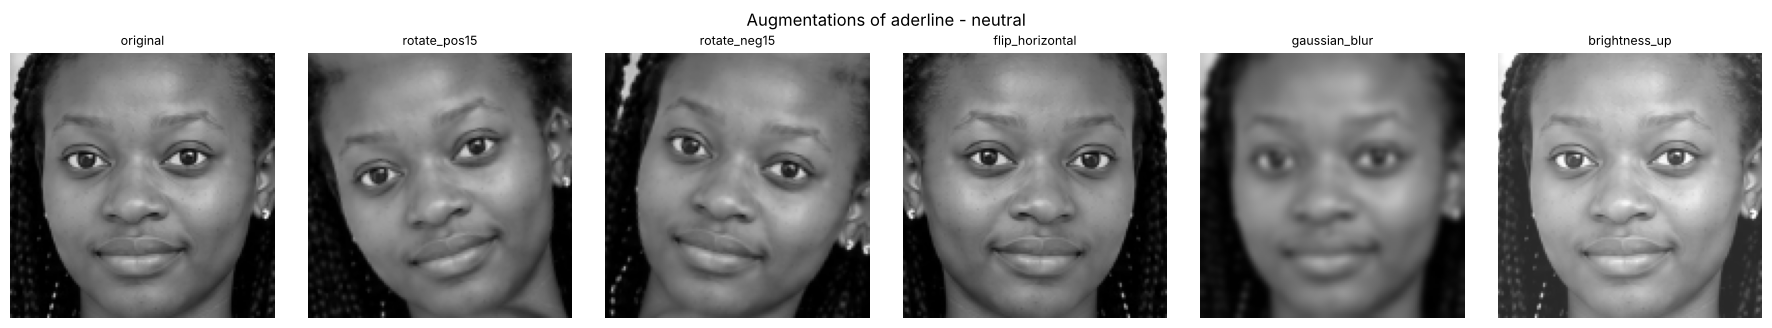

In [5]:
demo = items[0]
face = ip.crop_face(demo["bgr"])
fig, axes = plt.subplots(1, len(ip.AUGMENTATIONS), figsize=(3*len(ip.AUGMENTATIONS), 3.3))
for ax, (name, fn) in zip(axes, ip.AUGMENTATIONS.items()):
    ax.imshow(cv2.cvtColor(fn(face), cv2.COLOR_BGR2RGB)); ax.set_title(name, fontsize=9); ax.axis("off")
plt.suptitle(f"Augmentations of {demo['member']} - {demo['expression']}"); plt.tight_layout(); plt.show()

## 5. Feature extraction
Per image version we extract:
- **Grayscale intensity histogram:** 16 bins, normalised. It describes lighting and overall tone. All faces are converted to grayscale first, because the team's photos mix colour and black-and-white and the model must not learn that difference.
- **Brightness statistics:** grayscale mean and standard deviation.
- **HOG descriptor:** histogram of oriented gradients on a 64x64 grayscale face. It captures edge and shape structure (eyes, mouth, jaw), so it changes with expression and identity.

In [6]:
rows = []
for it in items:
    face = ip.crop_face(it["bgr"])
    for aug_name, fn in ip.AUGMENTATIONS.items():
        row = {"member": it["member"], "expression": it["expression"],
               "source_file": it["path"].name, "augmentation": aug_name}
        row.update(ip.extract_features(fn(face)))
        rows.append(row)
features = pd.DataFrame(rows)
Path("data").mkdir(exist_ok=True)
features.to_csv("data/image_features.csv", index=False)
print(features.shape, "| nulls:", int(features.isna().sum().sum()))
features.iloc[:6, :8]

(54, 346) | nulls: 0


,member,expression,source_file,augmentation,hist_gray_0,hist_gray_1,hist_gray_2,hist_gray_3
0,aderline,neutral,aderline_neutral.jpg,original,0.159668,0.051636,0.031555,0.028442
1,aderline,neutral,aderline_neutral.jpg,rotate_pos15,0.137390,0.052185,0.029236,0.033997
2,aderline,neutral,aderline_neutral.jpg,rotate_neg15,0.156982,0.041077,0.023010,0.026489
3,aderline,neutral,aderline_neutral.jpg,flip_horizontal,0.159668,0.051636,0.031555,0.028442
4,aderline,neutral,aderline_neutral.jpg,gaussian_blur,0.144104,0.063232,0.024353,0.030579
5,aderline,neutral,aderline_neutral.jpg,brightness_up,0.000000,0.000000,0.119507,0.070190


## 6. Sanity checks on the saved features

In [7]:
print(features.groupby(["member", "expression"]).size().unstack())
print("\nRows per augmentation:\n", features["augmentation"].value_counts().to_string())
feat_cols = [c for c in features.columns if c.startswith(("hist_", "hog_", "gray_"))]
print(f"\n{len(feat_cols)} feature columns; any infinite values: {np.isinf(features[feat_cols].values).any()}")

expression  neutral  smiling  surprised
member                                 
aderline          6        6          6
elox              6        6          6
sandrine          6        6          6

Rows per augmentation:
 augmentation
original           9
rotate_pos15       9
rotate_neg15       9
flip_horizontal    9
gaussian_blur      9
brightness_up      9

342 feature columns; any infinite values: False


## 7. Interpretation
**Augmentation effects (mean relative change in features vs the original image):**

| Augmentation | Intensity histogram | HOG shape descriptor |
|---|---|---|
| Brightness up | 0.74 | 0.02 |
| Rotate +15 / -15 | 0.08 / 0.07 | 0.38 / 0.37 |
| Horizontal flip | 0.00 | 0.41 |
| Gaussian blur | 0.09 | 0.20 |

The two feature groups capture different things. Brightness changes the histogram a lot but barely moves HOG, because HOG depends on edge directions, not absolute lightness. Rotation and flipping leave the histogram nearly unchanged, since the pixel values are the same, but they shift HOG strongly because the edge directions move. Together they give the model variants that differ in lighting, pose and sharpness.

**Feature space (PCA plot below):** in the first two components, Elox's neutral and surprised photos sit far to the left, apart from Aderline and Sandrine, who overlap on the right. They are still separable in the full 342-dimensional feature space, and the face model reached about 91% accuracy when a whole expression was held out. Elox's smiling photo is a clear outlier on PC2. It was taken in a different setting (blurred building background, different lighting and framing) from his other two photos, which were taken outdoors. So scene and lighting differences, not expression, dominate the first two components, and expressions are not cleanly separated by them. Photographing every member in the same place and lighting would make the features, and the face model's test, more reliable.

**Preprocessing:** a face was detected and cropped in every image (the largest detected face is used), and all faces were converted to grayscale so that colour differences between photos cannot leak identity.

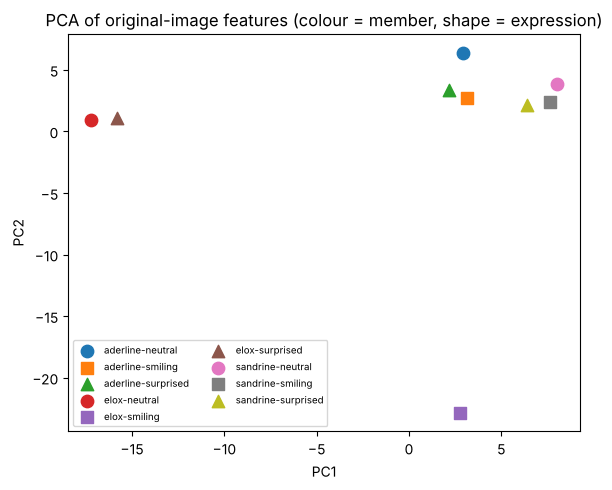

In [8]:
from sklearn.decomposition import PCA
orig = features[features.augmentation == "original"].reset_index(drop=True)
Z = PCA(n_components=2, random_state=0).fit_transform((orig[feat_cols] - orig[feat_cols].mean()) / (orig[feat_cols].std() + 1e-9))
fig, ax = plt.subplots(figsize=(6, 5))
markers = {"neutral": "o", "smiling": "s", "surprised": "^"}
for m in members:
    for e in ip.EXPRESSIONS:
        k = (orig.member == m) & (orig.expression == e)
        ax.scatter(Z[k, 0], Z[k, 1], label=f"{m}-{e}", marker=markers[e], s=80)
ax.set(title="PCA of original-image features (colour = member, shape = expression)", xlabel="PC1", ylabel="PC2")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()